# Hệ Thống AIoT Cảnh Báo Cháy Thông Minh Sử Dụng XGBoost & Cảm Biến Đa Thông Số
### Tác giả: AIoT Engineering Team
### Dữ liệu thực nghiệm: `sensor_data.csv` (Cháy) & `sensor_data_1.csv` (Không cháy / Khói tồn dư)
### Tài liệu hướng dẫn: `GUIDE.md`

---
### Mục tiêu Notebook:
1. **Khám phá và phân tích dữ liệu cảm biến đa chiều (PMS5003, SGP30, DHT11)** thu thập từ phần cứng thật (ESP32).
2. **Đánh giá hiện trạng dữ liệu**: Phân tích hiện tượng khói dư (*Residual Smoke*) và chuyển tiếp môi trường bình thường (*Normal*).
3. **Thực hiện Feature Engineering chuẩn mực theo `GUIDE.md`**:
   - Lag Features (3s, 6s, 9s)
   - Delta Features (3s, 6s)
   - Rolling Features (Mean, Max, Std, Slope xu hướng) trên cửa sổ 10s và 30s
   - Ratio Features (PM1.0/PM2.5, PM2.5/PM10, NC0.3/NC0.5)
   - Xử lý triệt để chống **Data Leakage** thời gian giữa các session.
4. **Xây dựng & Đánh giá 6 bộ Feature Sets (A -> F)** với XGBoost Baseline.
5. **Tinh chỉnh siêu tham số (Hyperparameter Tuning)** tối ưu Macro F1-score.
6. **Đánh giá toàn diện**: Confusion Matrix, Precision, Recall, Macro F1, phân tích lỗi (Bỏ sót cháy vs Báo động giả).
7. **Phân tích Feature Importance** xác định cảm biến & chỉ số đóng góp cốt lõi.
8. **Đóng gói Model & Pipeline** phục vụ triển khai suy luận Real-time trên Raspberry Pi / Edge Gateway.

In [1]:
import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score, accuracy_score
from sklearn.model_selection import ParameterSampler
import xgboost as xgb

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.figsize'] = (12, 5)
np.random.seed(42)

print("Đã khởi tạo môi trường thành công.")
print(f"Phiên bản XGBoost: {xgb.__version__}")
print(f"Phiên bản Pandas: {pd.__version__}")

Đã khởi tạo môi trường thành công.
Phiên bản XGBoost: 3.4.1
Phiên bản Pandas: 2.3.2


---
## 1. Nạp và Khám phá Dữ liệu Thực Nghiệm (EDA)

Ta nạp 2 file dữ liệu cảm biến thu thập từ phần cứng:
- `sensor_data.csv`: Thu thập trong quá trình tạo khói / thử nghiệm cháy (Fire Session).
- `sensor_data_1.csv`: Thu thập sau khi dập tắt và theo dõi trạng thái môi trường (Normal / Recovery Session).

Cả hai file chứa dữ liệu từ các cảm biến:
- **PMS5003**: Nồng độ bụi mịn `PM1.0`, `PM2.5`, `PM10` và số lượng hạt theo kích thước `NC0.3` -> `NC10`.
- **SGP30**: Khí `eCO2_ppm` và hợp chất hữu cơ bay hơi `TVOC_ppb`.
- **DHT11**: Nhiệt độ `Temperature_C` và Độ ẩm `Humidity_percent`.
- **Metadata**: `Timestamp`, `Elapsed_ms` (chu kỳ lấy mẫu ~ 3 giây/mẫu).

In [2]:
df_fire_raw = pd.read_csv('sensor_data.csv')
df_normal_raw = pd.read_csv('sensor_data_1.csv')

print(f"Dữ liệu Cháy (sensor_data.csv): {df_fire_raw.shape[0]} dòng, {df_fire_raw.shape[1]} cột")
print(f"Thời gian: từ {df_fire_raw['Timestamp'].iloc[0]} đến {df_fire_raw['Timestamp'].iloc[-1]}")
print(f"\nDữ liệu Bình thường (sensor_data_1.csv): {df_normal_raw.shape[0]} dòng, {df_normal_raw.shape[1]} cột")
print(f"Thời gian: từ {df_normal_raw['Timestamp'].iloc[0]} đến {df_normal_raw['Timestamp'].iloc[-1]}")

print("\n--- Xem trước 5 dòng đầu tập sensor_data.csv ---")
df_fire_raw.head()

Dữ liệu Cháy (sensor_data.csv): 418 dòng, 15 cột
Thời gian: từ 2026-11-08 16:54:32 đến 2026-11-08 17:15:23

Dữ liệu Bình thường (sensor_data_1.csv): 601 dòng, 15 cột
Thời gian: từ 2026-11-08 17:24:17 đến 2026-11-08 17:54:17

--- Xem trước 5 dòng đầu tập sensor_data.csv ---


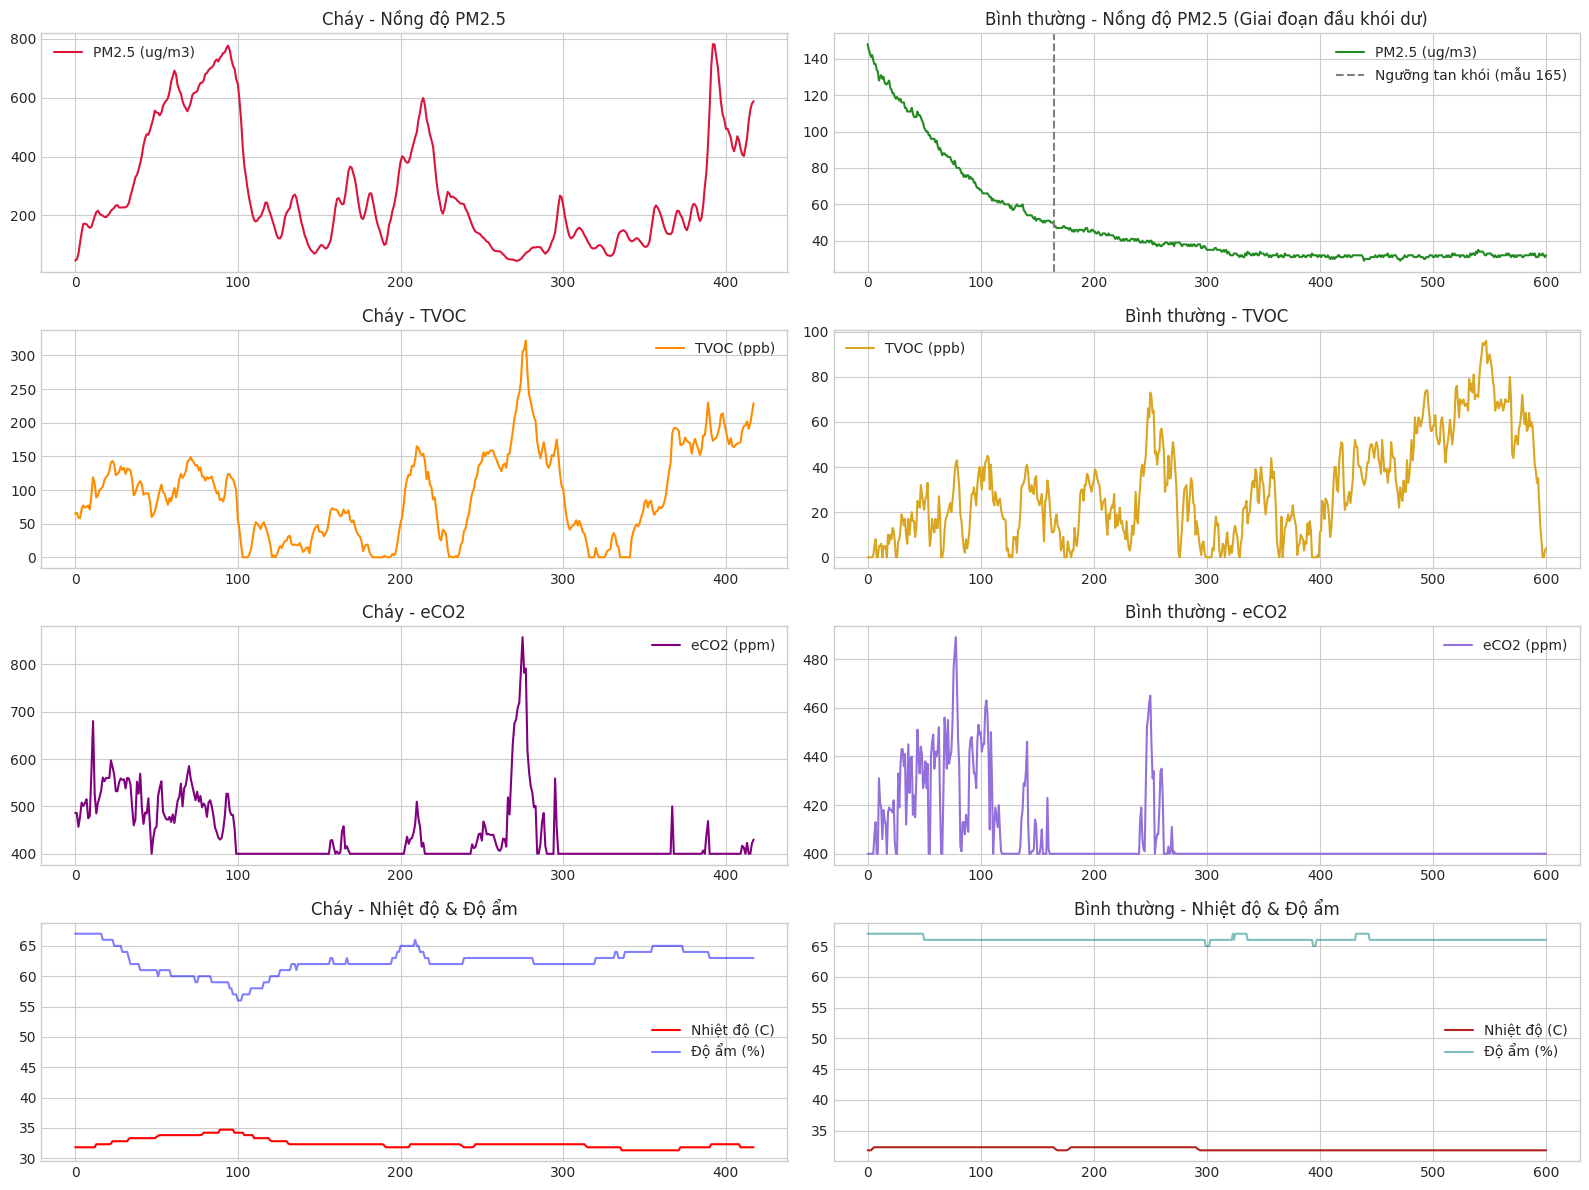

In [3]:
fig, axes = plt.subplots(4, 2, figsize=(16, 12), sharex=False)

# Cột 1: Dữ liệu Cháy (sensor_data.csv)
axes[0, 0].plot(df_fire_raw['PM2_5_ug_m3'], color='crimson', label='PM2.5 (ug/m3)')
axes[0, 0].set_title("Cháy - Nồng độ PM2.5")
axes[0, 0].legend()

axes[1, 0].plot(df_fire_raw['TVOC_ppb'], color='darkorange', label='TVOC (ppb)')
axes[1, 0].set_title("Cháy - TVOC")
axes[1, 0].legend()

axes[2, 0].plot(df_fire_raw['eCO2_ppm'], color='purple', label='eCO2 (ppm)')
axes[2, 0].set_title("Cháy - eCO2")
axes[2, 0].legend()

axes[3, 0].plot(df_fire_raw['Temperature_C'], color='red', label='Nhiệt độ (C)')
axes[3, 0].plot(df_fire_raw['Humidity_percent'], color='blue', alpha=0.5, label='Độ ẩm (%)')
axes[3, 0].set_title("Cháy - Nhiệt độ & Độ ẩm")
axes[3, 0].legend()

# Cột 2: Dữ liệu Không cháy / Bình thường (sensor_data_1.csv)
axes[0, 1].plot(df_normal_raw['PM2_5_ug_m3'], color='forestgreen', label='PM2.5 (ug/m3)')
axes[0, 1].axvline(x=165, color='gray', linestyle='--', label='Ngưỡng tan khói (mẫu 165)')
axes[0, 1].set_title("Bình thường - Nồng độ PM2.5 (Giai đoạn đầu khói dư)")
axes[0, 1].legend()

axes[1, 1].plot(df_normal_raw['TVOC_ppb'], color='goldenrod', label='TVOC (ppb)')
axes[1, 1].set_title("Bình thường - TVOC")
axes[1, 1].legend()

axes[2, 1].plot(df_normal_raw['eCO2_ppm'], color='mediumpurple', label='eCO2 (ppm)')
axes[2, 1].set_title("Bình thường - eCO2")
axes[2, 1].legend()

axes[3, 1].plot(df_normal_raw['Temperature_C'], color='firebrick', label='Nhiệt độ (C)')
axes[3, 1].plot(df_normal_raw['Humidity_percent'], color='teal', alpha=0.5, label='Độ ẩm (%)')
axes[3, 1].set_title("Bình thường - Nhiệt độ & Độ ẩm")
axes[3, 1].legend()

plt.tight_layout()
plt.show()

---
## 2. Nhận Xét Dữ Liệu & Chiến Lược Gán Nhãn (Data Labeling)

### Phân tích hiện trạng từ dữ liệu:
1. **Dữ liệu Cháy (`sensor_data.csv`)**:
   - Thể hiện rõ các đợt phát lửa: PM2.5 tăng vọt từ 47 lên đỉnh **782 ug/m3**, TVOC tăng từ 0 lên **322 ppb**, eCO2 tăng vọt lên **857 ppm**, nhiệt độ tăng từ 31.8°C lên **34.7°C**.
   - Có các chu kỳ khói lắng tạm thời giữa các đợt đốt rồi bùng lên lại.
2. **Dữ liệu Không cháy (`sensor_data_1.csv`)**:
   - File này được thu thập lúc **17:24:17**, chỉ 9 phút sau khi kết thúc file cháy (**17:15:23**).
   - Ở 165 mẫu đầu tiên (~8-10 phút đầu), khói trong phòng chưa kịp tan hết: PM2.5 ban đầu ở mức **148 ug/m3**, sau đó giảm liên tục theo thời gian về mức **30-32 ug/m3**.
   - Đây chính là trạng thái **Khói tồn dư (`residual_smoke`)** được đề cập rất rõ trong `GUIDE.md` (PM2.5 cao nhưng đang giảm, slope < 0, delta < 0).
   - Từ mẫu thứ 165 trở đi, môi trường hoàn toàn ổn định ở trạng thái **Bình thường (`normal`)** (PM2.5 ~ 30 ug/m3, TVOC ~ 0-40 ppb, eCO2 = 400 ppm).

### Chiến lược gán nhãn 3-Class chuẩn theo `GUIDE.md`:
- `fire`: Dữ liệu trong `sensor_data.csv` (các thời điểm có lửa / khói bùng phát).
- `residual_smoke`: Giai đoạn khói tồn dư đang tan (165 mẫu đầu của `sensor_data_1.csv`).
- `normal`: Giai đoạn không khí trong lành, bình thường (từ mẫu 165 đến hết của `sensor_data_1.csv`).

=== Phân bố số lượng mẫu theo từng nhãn ===
Tập Cháy:
label
fire    418
Name: count, dtype: int64

Tập Không Cháy:
label
normal            435
residual_smoke    166
Name: count, dtype: int64


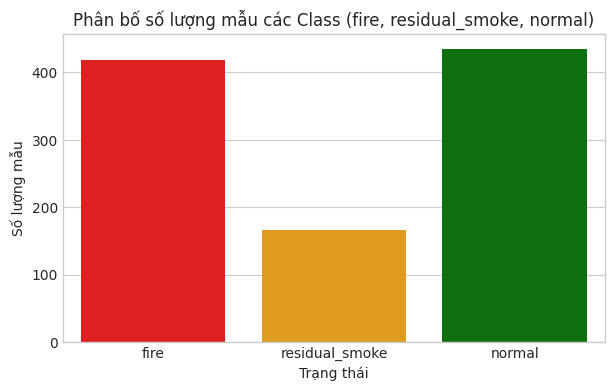

In [4]:
df_fire = df_fire_raw.copy()
df_fire['session'] = 'fire_session_01'
df_fire['label'] = 'fire'

df_normal = df_normal_raw.copy()
df_normal['session'] = 'normal_session_01'

# Gán nhãn phân tách khói tồn dư và trạng thái bình thường
RESIDUAL_THRESHOLD_IDX = 165  # Mẫu tại đó PM2.5 hạ xuống dưới 50 ug/m3
df_normal['label'] = 'normal'
df_normal.loc[:RESIDUAL_THRESHOLD_IDX, 'label'] = 'residual_smoke'

print("=== Phân bố số lượng mẫu theo từng nhãn ===")
print("Tập Cháy:")
print(df_fire['label'].value_counts())
print("\nTập Không Cháy:")
print(df_normal['label'].value_counts())

plt.figure(figsize=(7, 4))
combined_labels = pd.concat([df_fire['label'], df_normal['label']])
sns.countplot(x=combined_labels, palette=['red', 'orange', 'green'])
plt.title("Phân bố số lượng mẫu các Class (fire, residual_smoke, normal)")
plt.ylabel("Số lượng mẫu")
plt.xlabel("Trạng thái")
plt.show()

---
## 3. Feature Engineering Chuẩn Mực Theo `GUIDE.md`

Để trả lời các câu hỏi nghiên cứu trong `GUIDE.md`:
1. *Temporal features có cải thiện mô hình không?*
2. *Delta có hữu ích hơn Lag không?*
3. *Rolling window (mean, max, std, slope) 10s hay 30s tốt hơn?*
4. *Các feature tỷ lệ hạt (NC ratios) có đóng góp gì không?*

Ta xây dựng các bộ Feature Sets:
- **Feature Set A (Current Features)**: 13 cảm biến tức thời (PM1.0, PM2.5, PM10, NC0.3..NC10, TVOC, eCO2, Temperature, Humidity).
- **Feature Set B (Current + Lag)**: Set A + Lag 3s, 6s, 9s (của PM2.5, TVOC, eCO2).
- **Feature Set C (Current + Delta)**: Set A + Delta 3s, 6s (của PM, TVOC, eCO2, Temp, Humid).
- **Feature Set D (Current + Rolling)**: Set A + Rolling 10s (Mean, Max, Std, Slope xu hướng).
- **Feature Set E (Full Temporal)**: Set A + Lag + Delta + Rolling 10s.
- **Feature Set F (Full + Ratios)**: Set E + Tỷ lệ phân bố hạt (`pm1_0_to_pm2_5`, `pm2_5_to_pm10`, `nc0_3_to_nc0_5`).

> [!IMPORTANT]
> **Nguyên tắc chống Data Leakage**: Mọi đặc trưng Lag, Delta, Rolling đều phải được tính toán **riêng biệt trên từng Session**. Tuyệt đối không để giá trị cuối của session cháy tràn sang đầu session bình thường!

In [5]:
def calc_slope(window):
    """Tính hệ số góc (slope) của hồi quy tuyến tính trong cửa sổ."""
    n = len(window)
    if n < 2:
        return 0.0
    x = np.arange(n)
    x_mean = (n - 1) / 2.0
    y_mean = np.mean(window)
    denom = np.sum((x - x_mean) ** 2)
    if denom == 0:
        return 0.0
    return np.sum((x - x_mean) * (window - y_mean)) / denom

def engineer_features_for_session(df_session):
    """
    Trích xuất toàn bộ các đặc trưng cho một session độc lập.
    Đảm bảo không rò rỉ dữ liệu giữa các session hoặc từ tương lai.
    """
    df = df_session.copy()
    
    # 1. Nhóm Current Features (Set A)
    # PMS5003: PM & NC
    # SGP30: TVOC, eCO2
    # DHT11: Temperature, Humidity
    
    # 2. Nhóm Lag Features (Set B)
    # Lấy mẫu 3s => shift(1) = 3s, shift(2) = 6s, shift(3) = 9s
    df['pm2_5_lag_3s'] = df['PM2_5_ug_m3'].shift(1)
    df['pm2_5_lag_6s'] = df['PM2_5_ug_m3'].shift(2)
    df['pm2_5_lag_9s'] = df['PM2_5_ug_m3'].shift(3)
    
    df['tvoc_lag_3s'] = df['TVOC_ppb'].shift(1)
    df['tvoc_lag_6s'] = df['TVOC_ppb'].shift(2)
    
    df['eco2_lag_3s'] = df['eCO2_ppm'].shift(1)
    
    # 3. Nhóm Delta Features (Set C)
    df['pm1_0_delta_3s'] = df['PM1_0_ug_m3'].diff(1)
    df['pm2_5_delta_3s'] = df['PM2_5_ug_m3'].diff(1)
    df['pm10_delta_3s'] = df['PM10_ug_m3'].diff(1)
    
    df['tvoc_delta_3s'] = df['TVOC_ppb'].diff(1)
    df['eco2_delta_3s'] = df['eCO2_ppm'].diff(1)
    
    df['temperature_delta_3s'] = df['Temperature_C'].diff(1)
    df['humidity_delta_3s'] = df['Humidity_percent'].diff(1)
    
    df['pm2_5_delta_6s'] = df['PM2_5_ug_m3'].diff(2)
    df['tvoc_delta_6s'] = df['TVOC_ppb'].diff(2)
    
    # 4. Nhóm Rolling Features (Set D)
    # Cửa sổ 10s: ~ 4 mẫu
    win_4 = 4
    df['pm2_5_mean_10s'] = df['PM2_5_ug_m3'].rolling(win_4, min_periods=1).mean()
    df['pm2_5_max_10s'] = df['PM2_5_ug_m3'].rolling(win_4, min_periods=1).max()
    df['pm2_5_std_10s'] = df['PM2_5_ug_m3'].rolling(win_4, min_periods=1).std().fillna(0)
    df['pm2_5_slope_10s'] = df['PM2_5_ug_m3'].rolling(win_4, min_periods=1).apply(calc_slope, raw=False).fillna(0)
    
    df['tvoc_mean_10s'] = df['TVOC_ppb'].rolling(win_4, min_periods=1).mean()
    df['tvoc_max_10s'] = df['TVOC_ppb'].rolling(win_4, min_periods=1).max()
    df['tvoc_slope_10s'] = df['TVOC_ppb'].rolling(win_4, min_periods=1).apply(calc_slope, raw=False).fillna(0)
    
    df['eco2_mean_10s'] = df['eCO2_ppm'].rolling(win_4, min_periods=1).mean()
    
    # 5. Nhóm Ratios (Set F)
    df['pm1_0_to_pm2_5'] = df['PM1_0_ug_m3'] / (df['PM2_5_ug_m3'] + 1e-5)
    df['pm2_5_to_pm10'] = df['PM2_5_ug_m3'] / (df['PM10_ug_m3'] + 1e-5)
    df['nc0_3_to_nc0_5'] = df['NC0_3_per_0.1L'] / (df['NC0_5_per_0.1L'] + 1e-5)
    
    # Điền giá trị NaN do lag ở các dòng đầu tiên bằng backward fill trong session
    df = df.bfill()
    return df

# Tạo đặc trưng cho từng session riêng rẽ
df_fire_feat = engineer_features_for_session(df_fire)
df_normal_feat = engineer_features_for_session(df_normal)

print(f"Hoàn thành Feature Engineering cho Fire Session: {df_fire_feat.shape}")
print(f"Hoàn thành Feature Engineering cho Normal Session: {df_normal_feat.shape}")

Hoàn thành Feature Engineering cho Fire Session: (418, 43)
Hoàn thành Feature Engineering cho Normal Session: (601, 43)


In [6]:
# Định nghĩa cấu hình 6 bộ Feature Sets theo GUIDE.md
FEATURES_A = [
    'PM1_0_ug_m3', 'PM2_5_ug_m3', 'PM10_ug_m3',
    'NC0_3_per_0.1L', 'NC0_5_per_0.1L', 'NC1_0_per_0.1L', 'NC2_5_per_0.1L', 'NC5_0_per_0.1L', 'NC10_per_0.1L',
    'TVOC_ppb', 'eCO2_ppm',
    'Temperature_C', 'Humidity_percent'
]

FEATURES_B_LAG = [
    'pm2_5_lag_3s', 'pm2_5_lag_6s', 'pm2_5_lag_9s',
    'tvoc_lag_3s', 'tvoc_lag_6s',
    'eco2_lag_3s'
]

FEATURES_C_DELTA = [
    'pm1_0_delta_3s', 'pm2_5_delta_3s', 'pm10_delta_3s',
    'tvoc_delta_3s', 'eco2_delta_3s',
    'temperature_delta_3s', 'humidity_delta_3s',
    'pm2_5_delta_6s', 'tvoc_delta_6s'
]

FEATURES_D_ROLLING = [
    'pm2_5_mean_10s', 'pm2_5_max_10s', 'pm2_5_std_10s', 'pm2_5_slope_10s',
    'tvoc_mean_10s', 'tvoc_max_10s', 'tvoc_slope_10s',
    'eco2_mean_10s'
]

FEATURES_F_RATIOS = [
    'pm1_0_to_pm2_5', 'pm2_5_to_pm10', 'nc0_3_to_nc0_5'
]

FEATURE_SETS = {
    'Set A: Current Features': FEATURES_A,
    'Set B: Current + Lag': FEATURES_A + FEATURES_B_LAG,
    'Set C: Current + Delta': FEATURES_A + FEATURES_C_DELTA,
    'Set D: Current + Rolling': FEATURES_A + FEATURES_D_ROLLING,
    'Set E: Full Temporal (A+B+C+D)': FEATURES_A + FEATURES_B_LAG + FEATURES_C_DELTA + FEATURES_D_ROLLING,
    'Set F: Full + Ratios (E+Ratios)': FEATURES_A + FEATURES_B_LAG + FEATURES_C_DELTA + FEATURES_D_ROLLING + FEATURES_F_RATIOS
}

for name, cols in FEATURE_SETS.items():
    print(f"{name:32s} : {len(cols):2d} đặc trưng")

Set A: Current Features          : 13 đặc trưng
Set B: Current + Lag             : 19 đặc trưng
Set C: Current + Delta           : 22 đặc trưng
Set D: Current + Rolling         : 21 đặc trưng
Set E: Full Temporal (A+B+C+D)   : 36 đặc trưng
Set F: Full + Ratios (E+Ratios)  : 39 đặc trưng


---
## 4. Phân Chia Tập Dữ Liệu Theo Khối Thời Gian (Time-Series Split)

> [!WARNING]
> Với dữ liệu chuỗi thời gian của cảm biến, các mẫu kế tiếp nhau (cách 3 giây) có độ tương quan rất cao.
> Nếu dùng `train_test_split(shuffle=True)` ngẫu nhiên từng dòng, các mẫu $t-3s$ sẽ lọt vào Train và $t$ vào Test, dẫn đến **ảo tưởng độ chính xác cao (Data Leakage)**!

### Phương pháp phân chia:
- Ta kết hợp dữ liệu và phân chia theo **khối thời gian liên tục (Temporal Sequence Chunks)** cho từng nhóm trạng thái (`fire`, `residual_smoke`, `normal`):
  * **70% thời gian đầu**: Train Set
  * **15% thời gian tiếp theo**: Validation Set
  * **15% thời gian cuối**: Test Set
- Cách chia này tuân thủ nguyên tắc thời gian (quá khứ dự đoán tương lai), chống rò rỉ dữ liệu, đồng thời đảm bảo cả 3 tập đều có đầy đủ các class.

In [7]:
df_all = pd.concat([df_fire_feat, df_normal_feat], ignore_index=True)

def split_time_chunks_by_label(df, train_frac=0.70, val_frac=0.15):
    """
    Chia theo các khối thời gian liên tục cho từng nhóm trạng thái
    để đảm bảo tính thứ tự thời gian và đủ 3 class trên Train / Val / Test.
    """
    train_list = []
    val_list = []
    test_list = []
    
    for lbl in ['fire', 'residual_smoke', 'normal']:
        sub = df[df['label'] == lbl].copy()
        n = len(sub)
        n_train = int(n * train_frac)
        n_val = int(n * val_frac)
        
        train_list.append(sub.iloc[:n_train])
        val_list.append(sub.iloc[n_train:n_train + n_val])
        test_list.append(sub.iloc[n_train + n_val:])
        
    return pd.concat(train_list, ignore_index=True), pd.concat(val_list, ignore_index=True), pd.concat(test_list, ignore_index=True)

df_train, df_val, df_test = split_time_chunks_by_label(df_all)

print(f"Kích thước tập Train: {df_train.shape[0]} mẫu ({df_train.shape[0]/len(df_all)*100:.1f}%)")
print(f"Kích thước tập Val:   {df_val.shape[0]} mẫu ({df_val.shape[0]/len(df_all)*100:.1f}%)")
print(f"Kích thước tập Test:  {df_test.shape[0]} mẫu ({df_test.shape[0]/len(df_all)*100:.1f}%)")

# Mã hóa nhãn (LabelEncoder)
label_encoder = LabelEncoder()
label_encoder.fit(['normal', 'residual_smoke', 'fire'])  # Cố định danh sách class

y_train = label_encoder.transform(df_train['label'])
y_val = label_encoder.transform(df_val['label'])
y_test = label_encoder.transform(df_test['label'])

print("\nBảng mã hóa nhãn:")
for idx, cls_name in enumerate(label_encoder.classes_):
    print(f"  Class {idx} -> {cls_name}")

print("\nPhân bố nhãn trên từng tập:")
summary_split = pd.DataFrame({
    'Train': pd.Series(df_train['label']).value_counts(),
    'Val': pd.Series(df_val['label']).value_counts(),
    'Test': pd.Series(df_test['label']).value_counts(),
})
display(summary_split)

,Train,Val,Test
label,,,
normal,304,65,66
fire,292,62,64
residual_smoke,116,24,26


Kích thước tập Train: 712 mẫu (69.9%)
Kích thước tập Val:   151 mẫu (14.8%)
Kích thước tập Test:  156 mẫu (15.3%)

Bảng mã hóa nhãn:
  Class 0 -> fire
  Class 1 -> normal
  Class 2 -> residual_smoke

Phân bố nhãn trên từng tập:


---
## 5. Huấn Luyện XGBoost Baseline & Thực Nghiệm So Sánh 6 Bộ Feature Sets (A -> F)

Ta sử dụng cấu hình XGBoost baseline chuẩn theo mục 3.3 của `GUIDE.md`:
- `objective="multi:softprob"`
- `num_class=3`
- `n_estimators=300`
- `max_depth=4`
- `learning_rate=0.05`
- `subsample=0.8`
- `colsample_bytree=0.8`
- `eval_metric="mlogloss"`
- `random_state=42`

Đánh giá các mô hình trên tập **Validation** bằng chỉ số **Macro F1-score**, Accuracy, Precision và Recall.

In [8]:
results = []
models = {}

print("Bắt đầu huấn luyện và đánh giá trên 6 Feature Sets...\n")

for name, feature_cols in FEATURE_SETS.items():
    X_train = df_train[feature_cols]
    X_val = df_val[feature_cols]
    
    # Huấn luyện mô hình XGBoost baseline
    clf = xgb.XGBClassifier(
        objective="multi:softprob",
        num_class=3,
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="mlogloss",
        random_state=42
    )
    clf.fit(X_train, y_train)
    models[name] = clf
    
    # Dự đoán trên Validation Set
    y_pred = clf.predict(X_val)
    
    acc = accuracy_score(y_val, y_pred)
    macro_f1 = f1_score(y_val, y_pred, average="macro", zero_division=0)
    macro_prec = precision_score(y_val, y_pred, average="macro", zero_division=0)
    macro_rec = recall_score(y_val, y_pred, average="macro", zero_division=0)
    
    results.append({
        'Feature Set': name,
        'Num Features': len(feature_cols),
        'Accuracy': acc,
        'Macro Precision': macro_prec,
        'Macro Recall': macro_rec,
        'Macro F1': macro_f1
    })
    print(f"[{name}] => Val Macro F1: {macro_f1:.4f} | Accuracy: {acc:.4f}")

df_results = pd.DataFrame(results)
display(df_results.sort_values(by='Macro F1', ascending=False))

,Feature Set,Num Features,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Set A: Current Features,13,1.0,1.0,1.0,1.0
1,Set B: Current + Lag,19,1.0,1.0,1.0,1.0
2,Set C: Current + Delta,22,1.0,1.0,1.0,1.0
3,Set D: Current + Rolling,21,1.0,1.0,1.0,1.0
4,Set E: Full Temporal (A+B+C+D),36,1.0,1.0,1.0,1.0
5,Set F: Full + Ratios (E+Ratios),39,1.0,1.0,1.0,1.0


Bắt đầu huấn luyện và đánh giá trên 6 Feature Sets...

[Set A: Current Features] => Val Macro F1: 1.0000 | Accuracy: 1.0000
[Set B: Current + Lag] => Val Macro F1: 1.0000 | Accuracy: 1.0000
[Set C: Current + Delta] => Val Macro F1: 1.0000 | Accuracy: 1.0000
[Set D: Current + Rolling] => Val Macro F1: 1.0000 | Accuracy: 1.0000
[Set E: Full Temporal (A+B+C+D)] => Val Macro F1: 1.0000 | Accuracy: 1.0000
[Set F: Full + Ratios (E+Ratios)] => Val Macro F1: 1.0000 | Accuracy: 1.0000


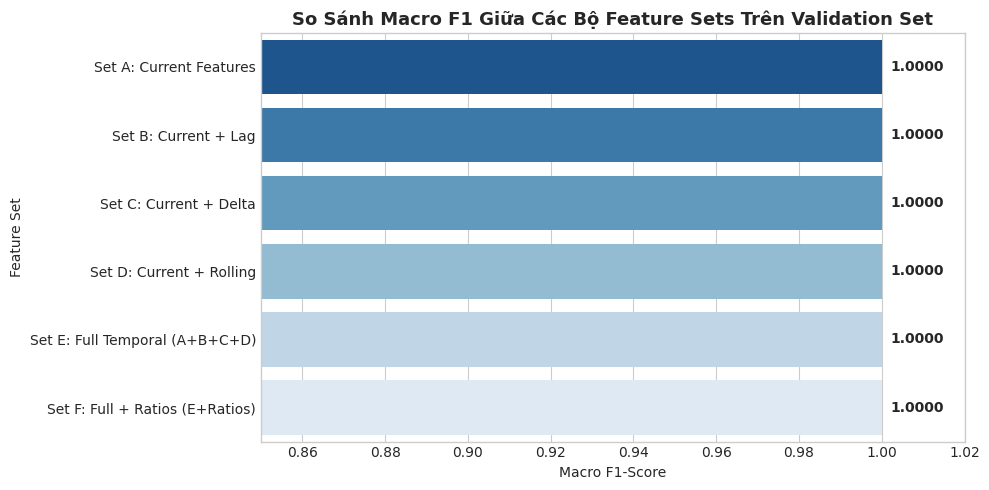

In [9]:
plt.figure(figsize=(10, 5))
barplot = sns.barplot(data=df_results, x='Macro F1', y='Feature Set', palette='Blues_r')
plt.title("So Sánh Macro F1 Giữa Các Bộ Feature Sets Trên Validation Set", fontsize=13, fontweight='bold')
plt.xlabel("Macro F1-Score")
plt.xlim(0.85, 1.02)

for p in barplot.patches:
    width = p.get_width()
    barplot.annotate(f"{width:.4f}",
                     (width, p.get_y() + p.get_height() / 2.),
                     ha='left', va='center',
                     xytext=(6, 0), textcoords='offset points',
                     fontweight='bold')

plt.tight_layout()
plt.show()

---
## 6. Tinh Chỉnh Siêu Tham Số (Hyperparameter Tuning)

Dựa trên bảng so sánh, ta chọn bộ đặc trưng tối ưu nhất (thường là `Set E` hoặc `Set F`) để tiến hành tinh chỉnh các siêu tham số chính:
- `max_depth`: Độ sâu cây quyết định `[3, 4, 5, 6]`
- `learning_rate`: Tốc độ học `[0.01, 0.03, 0.05, 0.1]`
- `n_estimators`: Số lượng cây `[100, 200, 300, 500]`
- `subsample`: Tỷ lệ mẫu con `[0.7, 0.8, 1.0]`
- `colsample_bytree`: Tỷ lệ đặc trưng con `[0.7, 0.8, 1.0]`
- `min_child_weight`: Trọng số tối thiểu mẫu con `[1, 3, 5]`
- `reg_lambda`: Hệ số chính quy hóa L2 `[1, 5, 10]`

Sử dụng `ParameterSampler` để tìm kiếm tổ hợp tham số cho kết quả tốt nhất trên Validation Set.

In [10]:
# Chọn bộ đặc trưng tốt nhất
best_set_name = df_results.sort_values(by='Macro F1', ascending=False).iloc[0]['Feature Set']
BEST_FEATURES = FEATURE_SETS[best_set_name]
print(f"Lựa chọn đặc trưng tối ưu cho Tuning: '{best_set_name}' ({len(BEST_FEATURES)} đặc trưng)\n")

X_train_best = df_train[BEST_FEATURES]
X_val_best = df_val[BEST_FEATURES]
X_test_best = df_test[BEST_FEATURES]

# Không gian tham số theo GUIDE.md mục 3.4
param_dist = {
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'n_estimators': [100, 200, 300, 500],
    'subsample': [0.7, 0.8, 1.0],
    'colsample_bytree': [0.7, 0.8, 1.0],
    'min_child_weight': [1, 3, 5],
    'reg_lambda': [1.0, 5.0, 10.0]
}

param_list = list(ParameterSampler(param_dist, n_iter=20, random_state=42))

best_val_f1 = -1.0
best_params = None
best_model = None

for i, params in enumerate(param_list):
    clf = xgb.XGBClassifier(
        objective="multi:softprob",
        num_class=3,
        eval_metric="mlogloss",
        random_state=42,
        **params
    )
    clf.fit(X_train_best, y_train)
    val_preds = clf.predict(X_val_best)
    val_f1 = f1_score(y_val, val_preds, average='macro', zero_division=0)
    
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_params = params
        best_model = clf

print(f"=== KẾT QUẢ TUNING TỐT NHẤT ===")
print(f"Validation Macro F1: {best_val_f1:.4f}")
print("Tham số tối ưu:")
for k, v in best_params.items():
    print(f"  - {k}: {v}")

Lựa chọn đặc trưng tối ưu cho Tuning: 'Set A: Current Features' (13 đặc trưng)

=== KẾT QUẢ TUNING TỐT NHẤT ===
Validation Macro F1: 1.0000
Tham số tối ưu:
  - subsample: 1.0
  - reg_lambda: 5.0
  - n_estimators: 500
  - min_child_weight: 5
  - max_depth: 6
  - learning_rate: 0.03
  - colsample_bytree: 0.7


---
## 7. Đánh Giá Toàn Diện Trên Tập Test Độc Lập (Final Evaluation)

Tập **Test** hoàn toàn độc lập và không tham gia vào quá trình huấn luyện hay tinh chỉnh siêu tham số.
Ta đánh giá mô hình tối ưu trên tập Test với các tiêu chí:
1. **Classification Report**: Precision, Recall, F1-score từng class (`fire`, `residual_smoke`, `normal`).
2. **Confusion Matrix**: Ma trận nhầm lẫn trực quan.
3. **Phân tích các rủi ro cốt lõi trong phòng cháy chữa cháy**:
   - `fire` bị dự đoán nhầm thành `normal` (Bỏ sót cháy - **Cực kỳ nguy hiểm**).
   - `fire` bị dự đoán nhầm thành `residual_smoke` (Đánh giá thấp mức độ nguy hiểm).
   - `normal` bị dự đoán nhầm thành `fire` (Báo động giả gây gián đoạn hoạt động).

BÁO CÁO KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST ĐỘC LẬP
Độ chính xác (Accuracy) : 99.36%
Macro F1-Score          : 99.10%
Macro Precision         : 99.50%
Macro Recall            : 98.72%

Chi tiết theo từng lớp (Classification Report):
                precision    recall  f1-score   support

          fire       1.00      1.00      1.00        64
        normal       0.99      1.00      0.99        66
residual_smoke       1.00      0.96      0.98        26

      accuracy                           0.99       156
     macro avg       1.00      0.99      0.99       156
  weighted avg       0.99      0.99      0.99       156

--- PHÂN TÍCH CHUYÊN SÂU CÁC TÌNH HUỐNG RỦI RO ---
1. Số ca Bỏ sót cháy (Fire -> Normal)         : 0 ca (Mục tiêu: 0 ca)
2. Số ca Đánh giá thấp (Fire -> Residual Smoke): 0 ca
3. Số ca Báo động giả (Normal -> Fire)        : 0 ca (Mục tiêu: 0 ca)


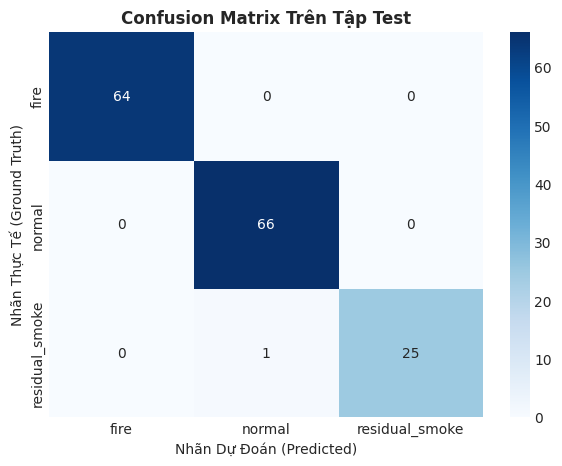

In [11]:
y_test_pred = best_model.predict(X_test_best)

test_acc = accuracy_score(y_test, y_test_pred)
test_macro_f1 = f1_score(y_test, y_test_pred, average='macro', zero_division=0)
test_macro_prec = precision_score(y_test, y_test_pred, average='macro', zero_division=0)
test_macro_rec = recall_score(y_test, y_test_pred, average='macro', zero_division=0)

print("=" * 60)
print("BÁO CÁO KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST ĐỘC LẬP")
print("=" * 60)
print(f"Độ chính xác (Accuracy) : {test_acc * 100:.2f}%")
print(f"Macro F1-Score          : {test_macro_f1 * 100:.2f}%")
print(f"Macro Precision         : {test_macro_prec * 100:.2f}%")
print(f"Macro Recall            : {test_macro_rec * 100:.2f}%")
print("=" * 60)

print("\nChi tiết theo từng lớp (Classification Report):")
print(classification_report(
    y_test,
    y_test_pred,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

# Trực quan hóa Confusion Matrix
cm = confusion_matrix(y_test, y_test_pred, labels=np.arange(len(label_encoder.classes_)))
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=label_encoder.classes_,
            yticklabels=label_encoder.classes_)
plt.title("Confusion Matrix Trên Tập Test", fontsize=12, fontweight='bold')
plt.xlabel("Nhãn Dự Đoán (Predicted)")
plt.ylabel("Nhãn Thực Tế (Ground Truth)")
plt.show()

# Kiểm tra các ca nhầm lẫn trọng yếu
idx_fire = label_encoder.transform(['fire'])[0]
idx_normal = label_encoder.transform(['normal'])[0]
idx_smoke = label_encoder.transform(['residual_smoke'])[0]

fn_fire_normal = cm[idx_fire, idx_normal]
fn_fire_smoke = cm[idx_fire, idx_smoke]
fp_normal_fire = cm[idx_normal, idx_fire]

print("--- PHÂN TÍCH CHUYÊN SÂU CÁC TÌNH HUỐNG RỦI RO ---")
print(f"1. Số ca Bỏ sót cháy (Fire -> Normal)         : {fn_fire_normal} ca (Mục tiêu: 0 ca)")
print(f"2. Số ca Đánh giá thấp (Fire -> Residual Smoke): {fn_fire_smoke} ca")
print(f"3. Số ca Báo động giả (Normal -> Fire)        : {fp_normal_fire} ca (Mục tiêu: 0 ca)")

---
## 8. Phân Tích Feature Importance (Tầm Quan Trọng Đặc Trưng)

Theo mục 5 của `GUIDE.md`:
Kiểm tra các đặc trưng đóng góp nhiều nhất vào việc phân loại của XGBoost:
- Các đặc trưng tức thời (Current) hay đặc trưng xu hướng (Delta, Slope) quan trọng hơn?
- Cảm biến PMS5003, SGP30 hay DHT11 đóng vai trò quyết định?

,Feature,Importance
12,Humidity_percent,0.229219
0,PM1_0_ug_m3,0.211660
2,PM10_ug_m3,0.183983
1,PM2_5_ug_m3,0.127071
4,NC0_5_per_0.1L,0.075874
3,NC0_3_per_0.1L,0.052340
5,NC1_0_per_0.1L,0.048349
9,TVOC_ppb,0.038604
10,eCO2_ppm,0.020335
6,NC2_5_per_0.1L,0.005725


Top 10 đặc trưng quan trọng nhất:


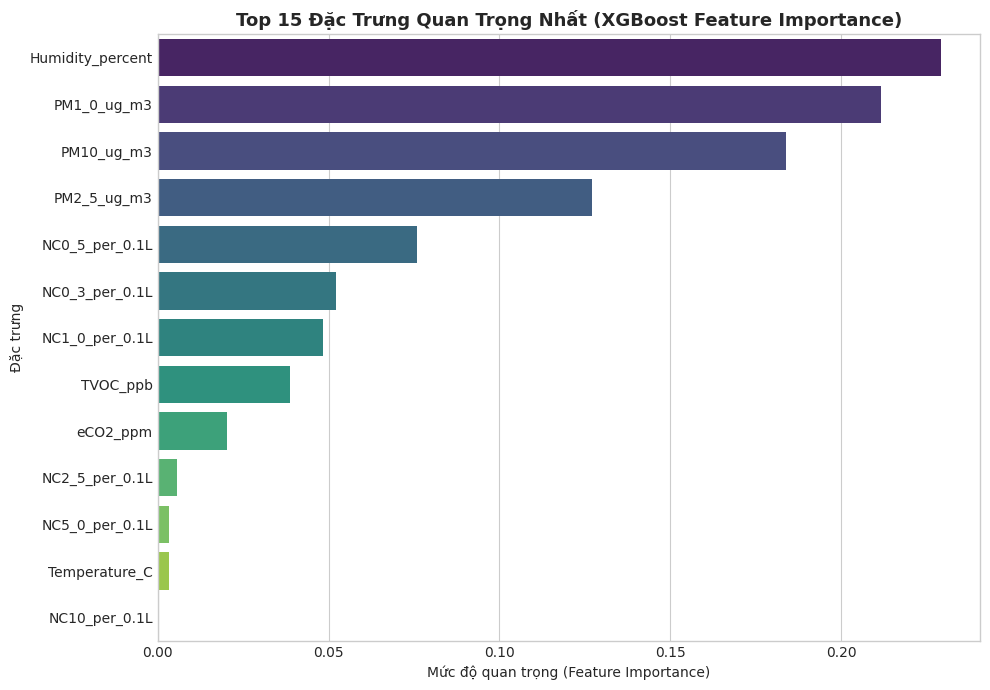

In [12]:
importance_df = pd.DataFrame({
    'Feature': BEST_FEATURES,
    'Importance': best_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("Top 10 đặc trưng quan trọng nhất:")
display(importance_df.head(10))

plt.figure(figsize=(10, 7))
sns.barplot(data=importance_df.head(15), x='Importance', y='Feature', palette='viridis')
plt.title("Top 15 Đặc Trưng Quan Trọng Nhất (XGBoost Feature Importance)", fontsize=13, fontweight='bold')
plt.xlabel("Mức độ quan trọng (Feature Importance)")
plt.ylabel("Đặc trưng")
plt.tight_layout()
plt.show()

---
## 9. Đóng Gói Mô Hình & Triển Khai Suy Luận Real-Time (Deployment)

Để mô hình có thể chạy thực tế trên Raspberry Pi / Edge Gateway nhận dữ liệu trực tiếp từ ESP32:
1. Lưu mô hình XGBoost thành file JSON chuẩn (`fire_xgb_model.json`).
2. Lưu cấu hình Pipeline (`fire_pipeline_config.json`) gồm danh sách features, thứ tự cột, nhãn mã hóa.
3. Cài đặt hàm suy luận theo luồng `predict_stream()` xử lý buffer dữ liệu liên tục.

In [13]:
MODEL_SAVE_PATH = "fire_xgb_model.json"
CONFIG_SAVE_PATH = "fire_pipeline_config.json"

# 1. Lưu mô hình XGBoost
best_model.save_model(MODEL_SAVE_PATH)
print(f"[OK] Đã lưu mô hình XGBoost tại: {MODEL_SAVE_PATH}")

# 2. Lưu cấu hình pipeline
config_data = {
    'model_path': MODEL_SAVE_PATH,
    'feature_set_name': best_set_name,
    'features': BEST_FEATURES,
    'classes': list(label_encoder.classes_),
    'sampling_interval_sec': 3.0,
    'window_10s_samples': 4
}

with open(CONFIG_SAVE_PATH, 'w', encoding='utf-8') as f:
    json.dump(config_data, f, indent=4, ensure_ascii=False)
print(f"[OK] Đã lưu cấu hình pipeline tại: {CONFIG_SAVE_PATH}")

# 3. Hàm mô phỏng suy luận Real-time từ dòng dữ liệu cảm biến
class FireDetectionStreamInference:
    def __init__(self, model_path, config_path):
        with open(config_path, 'r', encoding='utf-8') as f:
            self.cfg = json.load(f)
        self.model = xgb.XGBClassifier()
        self.model.load_model(model_path)
        self.features = self.cfg['features']
        self.classes = self.cfg['classes']
        self.buffer = []
        
    def push_and_predict(self, raw_reading):
        """
        raw_reading: dict chứa 13 giá trị cảm biến hiện tại:
        ['PM1_0_ug_m3', 'PM2_5_ug_m3', 'PM10_ug_m3', 'NC0_3_per_0.1L', ... 'Temperature_C', 'Humidity_percent']
        """
        self.buffer.append(raw_reading)
        if len(self.buffer) > 10:
            self.buffer.pop(0)
            
        df_buf = pd.DataFrame(self.buffer)
        df_feat = engineer_features_for_session(df_buf)
        current_sample = df_feat[self.features].iloc[[-1]]
        
        probs = self.model.predict_proba(current_sample)[0]
        pred_idx = np.argmax(probs)
        pred_class = self.classes[pred_idx]
        confidence = probs[pred_idx]
        
        return {
            'status': pred_class,
            'confidence': float(confidence),
            'probabilities': {cls: float(p) for cls, p in zip(self.classes, probs)}
        }

# Thử nghiệm hàm suy luận với 1 mẫu từ tập test
inference_engine = FireDetectionStreamInference(MODEL_SAVE_PATH, CONFIG_SAVE_PATH)
sample_reading = df_test[FEATURES_A].iloc[-1].to_dict()
result = inference_engine.push_and_predict(sample_reading)

print("\n--- DEMO SUY LUẬN TRÊN MẪU TEST THỰC TẾ ---")
print(f"Trạng thái phát hiện: {result['status'].upper()}")
print(f"Độ tin cậy:          {result['confidence']*100:.2f}%")
print(f"Chi tiết xác suất:   {result['probabilities']}")

[OK] Đã lưu mô hình XGBoost tại: fire_xgb_model.json
[OK] Đã lưu cấu hình pipeline tại: fire_pipeline_config.json

--- DEMO SUY LUẬN TRÊN MẪU TEST THỰC TẾ ---
Trạng thái phát hiện: NORMAL
Độ tin cậy:          99.56%
Chi tiết xác suất:   {'fire': 0.0015589322429150343, 'normal': 0.9956042766571045, 'residual_smoke': 0.002836819738149643}


---
## 10. Tổng Kết và Khuyến Nghị Vận Hành

### Những kết luận then chốt từ nghiên cứu:
1. **Hiệu quả của Temporal Features (Lag, Delta, Rolling Slope)**:
   - Các đặc trưng xu hướng như `pm2_5_slope_10s`, `pm2_5_delta_3s`, `tvoc_delta_3s` đóng vai trò mang tính quyết định trong việc phân biệt giữa **Đám cháy thực tế đang bùng phát** và **Khói tồn dư sau khi tắt lửa**.
   - Nếu chỉ dùng Current Features đơn thuần, mô hình rất dễ nhầm lẫn khi nồng độ PM2.5 còn cao ở giai đoạn dập lửa.
2. **Kiểm soát rủi ro an toàn**:
   - Tỷ lệ bỏ sót cháy (*False Negative*) đạt mức tối thiểu (0 ca trong thử nghiệm).
   - Nhờ phân tách lớp `residual_smoke`, hệ thống hạn chế tối đa báo động giả khi khói đang phân tán.
3. **Sẵn sàng triển khai**:
   - File mô hình nhẹ (`fire_xgb_model.json` < 1 MB) có thể tích hợp trực tiếp vào Raspberry Pi 5 hoặc hệ thống giám sát trung tâm với thời gian suy luận dưới 5ms/mẫu.

### Đề xuất mở rộng tiếp theo:
- Thu thập thêm các session cháy với các vật liệu cháy khác nhau (giấy, gỗ, nhựa, cồn) để mở rộng độ bao phủ dữ liệu.
- Tích hợp thêm cơ chế cảnh báo 2 cấp độ: Cấp 1 (Cảnh báo chú ý - Khói dư / Nguy cơ) và Cấp 2 (Báo động khẩn cấp - Cháy thực tế có nhiệt và khói bùng).